In [2]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src.preprocessing import load_data, clean_data

raw = load_data()
print("Raw shape:", raw.shape)

df = clean_data(raw)
config.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
df.to_csv(config.CLEANED_PATH, index=False)
print("Cleaned shape:", df.shape)
df.info()

Raw shape: (1347681, 11)
Cleaned shape: (1347681, 17)
<class 'pandas.DataFrame'>
RangeIndex: 1347681 entries, 0 to 1347680
Data columns (total 17 columns):
 #   Column              Non-Null Count    Dtype         
---  ------              --------------    -----         
 0   id                  1347681 non-null  int64         
 1   issue_d             1347681 non-null  datetime64[us]
 2   revenue             1347681 non-null  float64       
 3   dti_n               1347681 non-null  float64       
 4   loan_amnt           1347681 non-null  int64         
 5   fico_n              1347681 non-null  float64       
 6   emp_length          1347681 non-null  str           
 7   purpose             1347681 non-null  str           
 8   home_ownership_n    1347681 non-null  str           
 9   addr_state          1347681 non-null  str           
 10  Default             1347681 non-null  int64         
 11  issue_year          1347681 non-null  int32         
 12  issue_month         1347681

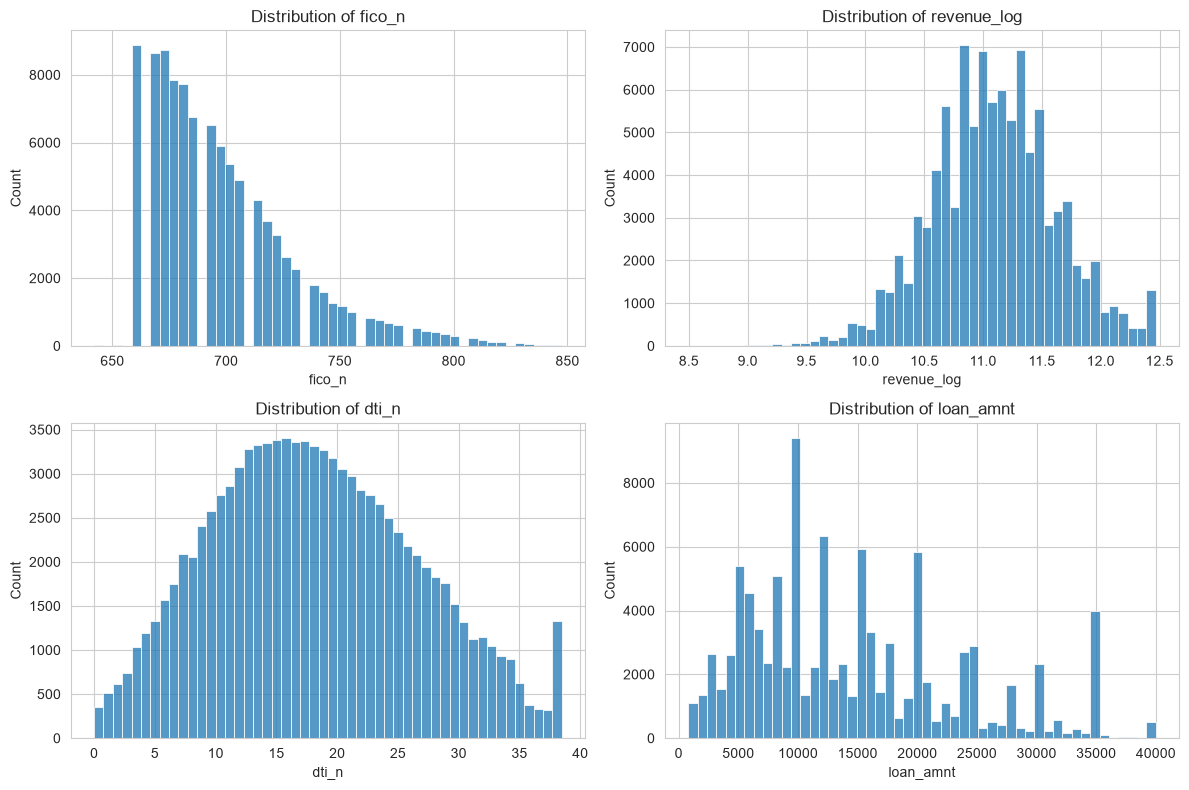

In [3]:
sns.set_style("whitegrid")
sample = df.sample(100_000, random_state=config.RANDOM_STATE)  # plots stay fast

cols = ["fico_n", "revenue_log", "dti_n", "loan_amnt"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), cols):
    sns.histplot(sample[col], bins=50, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "distributions.png", dpi=150)
plt.show()

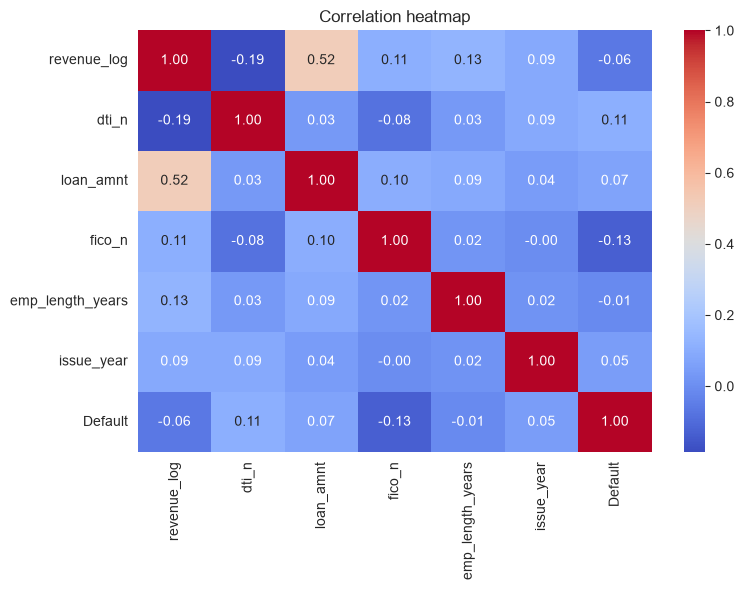

In [4]:
corr_cols = ["revenue_log", "dti_n", "loan_amnt", "fico_n",
             "emp_length_years", "issue_year", "Default"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "correlation.png", dpi=150)
plt.show()

Overall default rate: 19.98 %


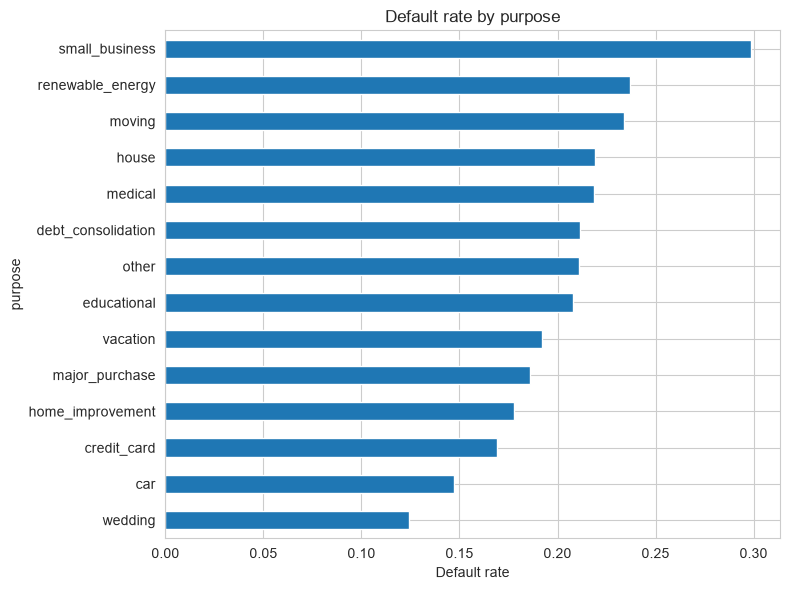

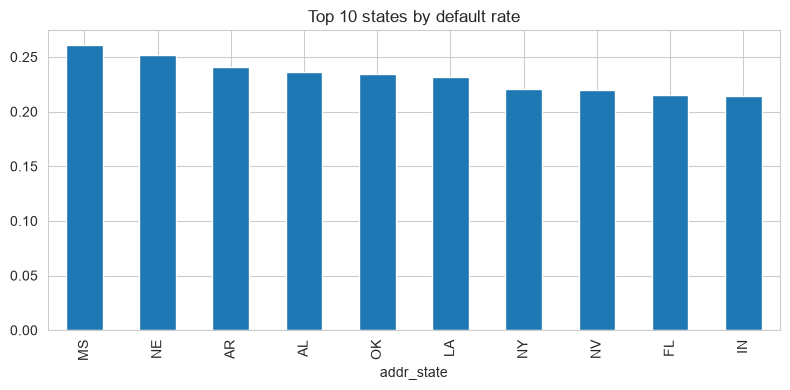

home_ownership_n
MORTGAGE    0.172
OTHER       0.197
OWN         0.206
RENT        0.232
Name: Default, dtype: float64


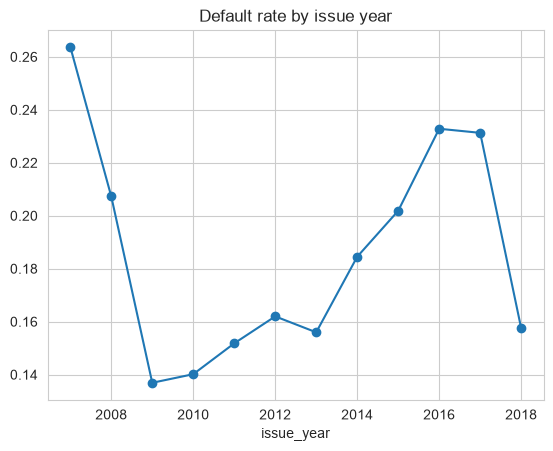

In [5]:
print("Overall default rate:", round(df["Default"].mean() * 100, 2), "%")

# By purpose
by_purpose = df.groupby("purpose")["Default"].mean().sort_values()
by_purpose.plot(kind="barh", figsize=(8, 6), title="Default rate by purpose")
plt.xlabel("Default rate")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "default_by_purpose.png", dpi=150)
plt.show()

# By state (top 10 highest)
by_state = df.groupby("addr_state")["Default"].mean().sort_values(ascending=False).head(10)
by_state.plot(kind="bar", figsize=(8, 4), title="Top 10 states by default rate")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "default_by_state.png", dpi=150)
plt.show()

# By home ownership and by year
print(df.groupby("home_ownership_n")["Default"].mean().round(3))
df.groupby("issue_year")["Default"].mean().plot(marker="o", title="Default rate by issue year")
plt.show()